# SPIQA — Adım 2 & 3: Ön İşleme ve Tokenizasyon

**Veri seti:** [`google/spiqa`](https://huggingface.co/datasets/google/spiqa) — bilimsel makalelerdeki şekil/tablo üzerine çoklu-modal soru-cevap veri seti (NeurIPS 2024).

Bu notebook ders planındaki şu iki adımı kapsıyor:

| Adım | İçerik | Notebook bölümü |
|---|---|---|
| **02** | Cleaning, normalization, segmentation | Bölüm 2–4 |
| **03** | Word and subword tokenization | Bölüm 5–7 |

**Önemli:** SPIQA'nın tamamı ~33.6 GB (görseller dahil). Biz sadece **metin** üzerinde çalışacağımız için
yalnızca `test-A` metadata JSON dosyasını indireceğiz (birkaç MB). `load_dataset("google/spiqa")` kullanmayın —
HF viewer'daki 666 satırlık sürüm sadece önizleme amaçlıdır, `all_figures` alanı boş gelir.

**Metin kaynaklarımız:** figure/table *caption*'ları, *question*, *answer* ve *rationale* alanları.
Bunlar bilimsel İngilizce metin → LaTeX matematik, atıf, kısaltma, sayı/metrik bolca var.
Ön işleme kararlarının neden önemli olduğunu (Adım 01) tam da burada göreceğiz.

## 0. Kurulum

In [19]:
# Gerekli paketler (Colab/yerel Jupyter'de bir kez çalıştırın)
%pip install -q huggingface_hub pandas nltk transformers tokenizers sentencepiece protobuf matplotlib
# Kurulumdan sonra: Kernel > Restart Kernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import json, re, unicodedata, os, random
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)
random.seed(42)
print("Hazır.")

Hazır.


## 1. Veriyi indir ve yapısını keşfet

SPIQA metadata'sı bir **sözlük**: anahtarlar arXiv makale ID'leri, değerler o makaleye ait
şekiller + soru-cevaplar.

In [9]:
from huggingface_hub import hf_hub_download

json_path = hf_hub_download(
    repo_id="google/spiqa",
    filename="test-A/SPIQA_testA.json",   # istersen "val"/"test-B"/"test-C" de alabilirsin
    repo_type="dataset",
    local_dir="spiqa_data",
)
print(json_path, f"{os.path.getsize(json_path)/1e6:.1f} MB")

with open(json_path, "r", encoding="utf-8") as f:
    meta = json.load(f)

print("Makale sayısı:", len(meta))
pid = list(meta.keys())[0]
print("Örnek paper_id:", pid)
print("Üst düzey alanlar:", list(meta[pid].keys()))

spiqa_data\test-A\SPIQA_testA.json 0.8 MB
Makale sayısı: 118
Örnek paper_id: 1611.04684v1
Üst düzey alanlar: ['paper_id', 'all_figures', 'qa']


In [10]:
# Bir makalenin içine bakalım: şekiller ve QA'ler nasıl duruyor?
sample = meta[pid]

fig_key = "all_figures" if "all_figures" in sample else list(sample.keys())[0]
first_fig_name = list(sample[fig_key].keys())[0]
print("--- Şekil kaydı ---")
print(first_fig_name)
print(json.dumps(sample[fig_key][first_fig_name], indent=2)[:600])

print("\n--- QA kaydı ---")
print(json.dumps(sample["qa"][0], indent=2)[:800])

--- Şekil kaydı ---
1611.04684v1-Table3-1.png
{
  "caption": "Table 3: Evaluation results on answer selection",
  "content_type": "table",
  "figure_type": "N/A"
}

--- QA kaydı ---
{
  "question": "What are the main differences between the educational philosophies of the Bonaparte and Voltaire schools?",
  "answer": "The Bonaparte school focuses on outdoor physical activities, maneuvers, and strategies, with a specialization in horse riding, lances, and swords. They aim to develop students into good leaders. The Voltaire school, on the other hand, encourages independent thinking and focuses on indoor activities. They aim to instill good moral values and develop students into philosophical thinkers.",
  "explanation": "The figure presents a question and answer format, where the answer explicitly describes the contrasting educational approaches of the two schools.",
  "reference": "1611.04684v1-Table1-1.png"
}


### 1.1 Düz (flat) bir tabloya dönüştür

Her metin parçasını ayrı bir satır yapıyoruz; böylece `source` sütunuyla
caption / question / answer / rationale'ı karşılaştırabiliriz.

In [11]:
rows = []
for paper_id, item in meta.items():
    # --- Şekil ve tablo caption'ları ---
    for fname, f in item.get("all_figures", {}).items():
        if not isinstance(f, dict):
            continue
        rows.append({
            "paper_id": paper_id,
            "source": "caption",
            "ref": fname,
            "content_type": f.get("content_type"),   # figure | table
            "figure_type": f.get("figure_type"),     # schematic | plot | photo | ...
            "text": f.get("caption", "") or "",
        })
    # --- Soru / cevap / gerekçe ---
    for qa in item.get("qa", []):
        if not isinstance(qa, dict):
            continue
        ref = qa.get("reference") or qa.get("reference_figure") or ""
        for field, label in [("question", "question"), ("answer", "answer"), ("rationale", "rationale")]:
            txt = qa.get(field)
            if isinstance(txt, str) and txt.strip():
                rows.append({"paper_id": paper_id, "source": label, "ref": str(ref),
                             "content_type": None, "figure_type": None, "text": txt})

df = pd.DataFrame(rows)
print("Toplam metin parçası:", len(df))
print(df["source"].value_counts(), "\n")
df.head(5)

Toplam metin parçası: 2447
source
caption     1115
question     666
answer       666
Name: count, dtype: int64 



,paper_id,source,ref,content_type,figure_type,text
0,1611.04684v1,caption,1611.04684v1-Table3-1.png,table,N/A,Table 3: Evaluation results on answer selection
1,1611.04684v1,caption,1611.04684v1-Table2-1.png,table,N/A,Table 2: Statistics of the answer selection data set
2,1611.04684v1,caption,1611.04684v1-Table1-1.png,table,other,A difficult example from QA
3,1611.04684v1,caption,1611.04684v1-Table4-1.png,table,N/A,Table 4: Evaluation results on response selection
4,1611.04684v1,caption,1611.04684v1-Table5-1.png,table,table,Accuracy on different length of text


In [12]:
# Ham metinde ne tür gürültü var? Rastgele örneklere bakalım.
for _, r in df.sample(8, random_state=7).iterrows():
    print(f"[{r['source']}] {r['text'][:220]}")
    print("-" * 90)

[answer]  The four steps involved in the synonym discovery process are: 

1. **Entity representation learning:** Learn entity representations from the corpus using WEMBED.
2. **NN search:** Perform a nearest neighbor search to fi
------------------------------------------------------------------------------------------
[caption] Illustrating the building blocks: (a) Two residual blocks; (b) An inception-like block; (c) A merge-and-run block. (a) corresponds to two blocks in ResNets and assembles two residual branches sequentially while (b) and (
------------------------------------------------------------------------------------------
[caption] Table 2: Recommendation accuracy with additional samples and different loss functions compared to item-kNN and the original GRU4Rec. Improvements over item-kNN and the original GRU4Rec (with TOP1 loss) results are shown 
------------------------------------------------------------------------------------------
[caption] Table 1: Properties of th

## 2. CLEANING (Temizleme) — Adım 02 / bölüm 1

Bilimsel metinde tipik gürültüler:

| Sorun | Örnek | Neden önemli? |
|---|---|---|
| LaTeX matematik | `R$_{10}$@1`, `$\alpha$` | Tokenizer'ı bozar, anlamsız token patlaması yaratır |
| LaTeX komutları | `\cite{xyz}`, `\ref{fig:1}`, `\%` | İçerik taşımaz |
| Şekil/tablo atıfları | `Figure 3`, `Table 1(a)` | İsteğe bağlı: `<FIG>` ile normalize edilebilir |
| URL / e-posta | `https://github.com/...` | Sözlüğü şişirir |
| Satır sonu tireleme | `represen-\ntation` | Kelimeyi ikiye böler |
| Unicode varyantları | `“ ” – — ×` | Aynı karakterin farklı kodları |
| Fazla boşluk, kontrol karakterleri | `\u00a0`, `\t` | Tokenizasyonu bozar |

> **Tasarım kararı:** Bilgiyi *silmek* yerine **yer tutucuya (placeholder)** çevirmek genelde daha iyidir.
> `<MATH>`, `<NUM>`, `<URL>` gibi etiketler bilgiyi korur ama sözlüğü şişirmez.
> Her adımı açılıp kapanabilir yaptık ki derste etkisini ölçebilesiniz.

In [13]:
RE_CONTROL   = re.compile(r"[\u0000-\u0008\u000b\u000c\u000e-\u001f\u007f]")
RE_DEHYPHEN  = re.compile(r"(\w+)-\s*\n\s*(\w+)")
RE_URL       = re.compile(r"https?://\S+|www\.\S+")
RE_EMAIL     = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.]+\b")
RE_TEX_CMD   = re.compile(r"\\(?:cite|citep|citet|ref|eqref|label|footnote)\s*\{[^}]*\}")
RE_TEX_LEFT  = re.compile(r"\\(?:left|right|text|mathrm|mathbf|textit|textbf|emph)\b")
RE_MATH      = re.compile(r"\$\$?.+?\$\$?", re.DOTALL)        # $...$ ve $$...$$
RE_FIGREF    = re.compile(r"\b(?:Fig(?:ure)?|Tab(?:le)?)\.?\s*~?\s*\d+[a-zA-Z]?(?:\([a-z]\))?", re.I)
RE_NUM       = re.compile(r"(?<![\w.])[-+]?\d+(?:[.,]\d+)*%?(?![\w])")
RE_WS        = re.compile(r"\s+")

def clean_text(
    text,
    dehyphenate=True,
    mask_math=True,
    mask_url=True,
    mask_figref=False,   # derste açıp kapatıp etkisini ölçün
    mask_num=False,      # sayılar SPIQA'da anlam taşıyor (metrik değerleri) -> varsayılan kapalı
    unicode_form="NFKC",
):
    # SPIQA metinleri için yapılandırılabilir temizleyici.
    if not isinstance(text, str):
        return ""
    t = unicodedata.normalize(unicode_form, text)   # “ ” -> " " , ﬁ -> fi , NBSP -> space
    t = RE_CONTROL.sub(" ", t)
    if dehyphenate:
        t = RE_DEHYPHEN.sub(r"\1\2", t)
    if mask_url:
        t = RE_URL.sub(" <URL> ", t)
        t = RE_EMAIL.sub(" <EMAIL> ", t)
    t = RE_TEX_CMD.sub(" ", t)
    t = RE_TEX_LEFT.sub(" ", t)
    if mask_math:
        t = RE_MATH.sub(" <MATH> ", t)
    t = t.replace("\\", " ")                        # artık kalan ters bölü işaretleri
    if mask_figref:
        t = RE_FIGREF.sub(" <FIGREF> ", t)
    if mask_num:
        t = RE_NUM.sub(" <NUM> ", t)
    t = RE_WS.sub(" ", t).strip()
    return t

In [14]:
# Önce / sonra karşılaştırması: en çok LaTeX içeren örnekleri seçelim
noisy = df[df["text"].str.contains(r"\$|\\\\|Figure|Table", regex=True, na=False)]
for _, r in noisy.sample(min(5, len(noisy)), random_state=3).iterrows():
    print("HAM   :", r["text"][:200])
    print("TEMİZ :", clean_text(r["text"])[:200])
    print("-" * 95)

HAM   : Table 1: Description of evaluation datasets.
TEMİZ : Table 1: Description of evaluation datasets.
-----------------------------------------------------------------------------------------------
HAM   : Figure 5. Samples generated by ITN with different thresholds Tu. The number below each sample represents the threshold.
TEMİZ : Figure 5. Samples generated by ITN with different thresholds Tu. The number below each sample represents the threshold.
-----------------------------------------------------------------------------------------------
HAM   : Table 1. Performance of different algorithms for k-shot binary classification problem
TEMİZ : Table 1. Performance of different algorithms for k-shot binary classification problem
-----------------------------------------------------------------------------------------------
HAM   : Table 1: Comparison of the GBI vs. A*inference procedure for SRL. We report the avg. disagreement rate, F1-scores and exact match for the failure set (col

In [15]:
df["clean"] = df["text"].apply(clean_text)

# Temizliğin nicel etkisi
before_chars = df["text"].str.len().sum()
after_chars  = df["clean"].str.len().sum()
print(f"Karakter: {before_chars:,} -> {after_chars:,}  ({100*(before_chars-after_chars)/before_chars:.1f}% azalma)")

vocab_raw   = Counter(w for t in df["text"]  for w in t.split())
vocab_clean = Counter(w for t in df["clean"] for w in t.split())
print(f"Boşlukla ayrılmış tip sayısı: {len(vocab_raw):,} -> {len(vocab_clean):,}")

Karakter: 389,338 -> 388,929  (0.1% azalma)
Boşlukla ayrılmış tip sayısı: 10,303 -> 10,251


## 3. NORMALIZATION (Normalleştirme) — Adım 02 / bölüm 2

Burada kritik bir ders noktası var: **normalleştirme her zaman faydalı değildir.**
Yapacağınız modele göre karar verin.

| İşlem | Ne zaman iyi | Ne zaman zararlı |
|---|---|---|
| Lowercasing | Klasik BoW/TF-IDF, uncased modeller | `BERT` vs `bert`, `US` vs `us`; cased modellerde bilgi kaybı |
| Noktalama silme | Bag-of-words | Soru cümlelerinde `?` sinyaldir |
| Stopword silme | Anahtar kelime çıkarımı | QA'da `what`, `how`, `not` anlamı taşır → **silmeyin** |
| Stemming/Lemmatization | Klasik IR | Transformer tabanlı modellerde gereksiz |

Aşağıda hepsini uygulayıp **etkisini ölçüyoruz**, körlemesine uygulamıyoruz.

In [16]:
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception as e:
        print("indirilemedi:", pkg, e)

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

STOP = set(stopwords.words("english"))
stemmer, lemmatizer = PorterStemmer(), WordNetLemmatizer()

def normalize(text, lowercase=True, strip_punct=False, remove_stop=False,
              stem=False, lemma=False):
    t = text.lower() if lowercase else text
    # <MATH>/<URL> gibi yer tutucuları tek token olarak koru (lowercase sonrası <math> de olabilir)
    toks = re.findall(r"<[A-Za-z]+>|\w+(?:[-']\w+)*|[^\w\s]", t)
    if strip_punct:
        toks = [w for w in toks if re.search(r"\w", w)]
    if remove_stop:
        toks = [w for w in toks if w.lower() not in STOP]
    if stem:
        toks = [stemmer.stem(w) for w in toks]
    if lemma:
        toks = [lemmatizer.lemmatize(w) for w in toks]
    return toks

demo = df[df["source"] == "question"]["clean"].iloc[3]
print("Girdi:", demo, "\n")
for name, kw in [
    ("baseline (sadece lowercase)", {}),
    ("+ noktalama silme",            {"strip_punct": True}),
    ("+ stopword silme",             {"strip_punct": True, "remove_stop": True}),
    ("+ stemming",                   {"strip_punct": True, "remove_stop": True, "stem": True}),
    ("+ lemmatization",              {"strip_punct": True, "remove_stop": True, "lemma": True}),
]:
    print(f"{name:32s}: {normalize(demo, **kw)}")

Girdi: What is the role of the knowledge gates in the KEHNN architecture? 

baseline (sadece lowercase)     : ['what', 'is', 'the', 'role', 'of', 'the', 'knowledge', 'gates', 'in', 'the', 'kehnn', 'architecture', '?']
+ noktalama silme               : ['what', 'is', 'the', 'role', 'of', 'the', 'knowledge', 'gates', 'in', 'the', 'kehnn', 'architecture']
+ stopword silme                : ['role', 'knowledge', 'gates', 'kehnn', 'architecture']
+ stemming                      : ['role', 'knowledg', 'gate', 'kehnn', 'architectur']
+ lemmatization                 : ['role', 'knowledge', 'gate', 'kehnn', 'architecture']


In [17]:
# Sözlük boyutuna etkisi — hangi normalleştirme ne kadar sıkıştırıyor?
sub = df["clean"].sample(min(4000, len(df)), random_state=0).tolist()

configs = {
    "ham (lowercase yok)":  dict(lowercase=False),
    "lowercase":            dict(),
    "+noktalama silme":     dict(strip_punct=True),
    "+stopword silme":      dict(strip_punct=True, remove_stop=True),
    "+stemming":            dict(strip_punct=True, remove_stop=True, stem=True),
    "+lemmatization":       dict(strip_punct=True, remove_stop=True, lemma=True),
}
res = []
for name, kw in configs.items():
    toks = [w for t in sub for w in normalize(t, **kw)]
    res.append({"config": name, "token": len(toks), "tip (vocab)": len(set(toks))})
norm_table = pd.DataFrame(res)
display(norm_table)

,config,token,tip (vocab)
0,ham (lowercase yok),74789,6651
1,lowercase,74789,5781
2,+noktalama silme,62190,5716
3,+stopword silme,39098,5600
4,+stemming,39098,4202
5,+lemmatization,39098,5082


## 4. SEGMENTATION (Bölütleme) — Adım 02 / bölüm 3

Cümlelere bölme göründüğü kadar kolay değil. Bilimsel metinde nokta şu durumlarda **cümle sonu değildir**:
`Fig. 3`, `et al.`, `e.g.`, `vs.`, `0.785`, `Eq. (2)`.

Naif `split(".")` ile NLTK Punkt'u karşılaştıralım.

In [18]:
from nltk.tokenize import sent_tokenize

tricky = ("As shown in Fig. 3, the model of Wu et al. reaches 0.785 accuracy, i.e. a 2.1% gain. "
          "We compare this vs. the baseline in Table 1.")

print("NAİF  :", [s.strip() for s in tricky.split(".") if s.strip()], "\n")
print("PUNKT :", sent_tokenize(tricky))

NAİF  : ['As shown in Fig', '3, the model of Wu et al', 'reaches 0', '785 accuracy, i', 'e', 'a 2', '1% gain', 'We compare this vs', 'the baseline in Table 1'] 

PUNKT : ['As shown in Fig.', '3, the model of Wu et al.', 'reaches 0.785 accuracy, i.e.', 'a 2.1% gain.', 'We compare this vs. the baseline in Table 1.']


Toplam cümle: 3634
Cümle uzunluğu (kelime) — ort: 14.0, medyan: 13, p95: 31


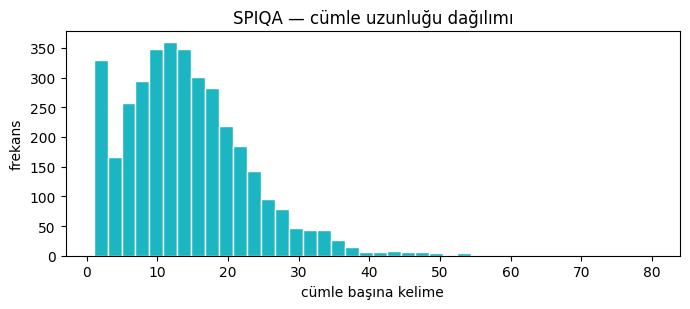

In [19]:
# Tüm korpusu cümlelere böl (uzun alanlar: answer ve rationale)
long_df = df[df["source"].isin(["answer", "rationale", "caption"])].copy()
long_df["sents"] = long_df["clean"].apply(lambda t: sent_tokenize(t) if t else [])

sent_df = long_df.explode("sents").dropna(subset=["sents"])
sent_df = sent_df[sent_df["sents"].str.len() > 0]
print("Toplam cümle:", len(sent_df))

lens = sent_df["sents"].str.split().apply(len)
print(f"Cümle uzunluğu (kelime) — ort: {lens.mean():.1f}, medyan: {lens.median():.0f}, p95: {lens.quantile(.95):.0f}")

plt.figure(figsize=(7, 3.2))
plt.hist(lens.clip(upper=80), bins=40, color="#1BB6C1", edgecolor="white")
plt.xlabel("cümle başına kelime"); plt.ylabel("frekans")
plt.title("SPIQA — cümle uzunluğu dağılımı"); plt.tight_layout(); plt.show()

## 5. WORD TOKENIZATION (Kelime tokenizasyonu) — Adım 03 / bölüm 1

Üç yaklaşımı aynı cümlede karşılaştıralım:
1. **Whitespace** — en naif
2. **Regex** — kendi kurallarımız
3. **NLTK Treebank** — dil bilgisi kurallı

Dikkat edin: `don't`, `state-of-the-art`, `<MATH>` gibi durumlarda üçü farklı davranır.

In [20]:
from nltk.tokenize import word_tokenize, RegexpTokenizer

regex_tok = RegexpTokenizer(r"<[A-Za-z]+>|\w+(?:[-']\w+)*|\S")

s = "We don't use state-of-the-art CNNs; the F1-score was <MATH> (see Table 2)."
print("whitespace :", s.split())
print("regex      :", regex_tok.tokenize(s))
print("nltk       :", word_tokenize(s))

whitespace : ['We', "don't", 'use', 'state-of-the-art', 'CNNs;', 'the', 'F1-score', 'was', '<MATH>', '(see', 'Table', '2).']
regex      : ['We', "don't", 'use', 'state-of-the-art', 'CNNs', ';', 'the', 'F1-score', 'was', '<MATH>', '(', 'see', 'Table', '2', ')', '.']
nltk       : ['We', 'do', "n't", 'use', 'state-of-the-art', 'CNNs', ';', 'the', 'F1-score', 'was', '<', 'MATH', '>', '(', 'see', 'Table', '2', ')', '.']


In [21]:
# Sözlük istatistikleri ve OOV problemi
corpus = df["clean"].tolist()
word_tokens = [w.lower() for t in corpus for w in regex_tok.tokenize(t)]
vocab = Counter(word_tokens)

print(f"Toplam token: {len(word_tokens):,}")
print(f"Sözlük (tip) : {len(vocab):,}")
hapax = sum(1 for c in vocab.values() if c == 1)
print(f"Sadece 1 kez geçen kelime (hapax): {hapax:,}  ({100*hapax/len(vocab):.1f}%)")
print("\nEn sık 20 token:", vocab.most_common(20))

Toplam token: 74,789
Sözlük (tip) : 5,781
Sadece 1 kez geçen kelime (hapax): 2,114  (36.6%)

En sık 20 token: [('the', 5592), ('.', 3930), ('of', 2145), (',', 2101), ('and', 1721), (')', 1610), ('(', 1558), ('in', 1077), ('to', 1018), ('a', 921), ('is', 915), ('for', 843), ('on', 841), (':', 693), ('?', 677), ('with', 614), ('are', 478), ('model', 441), ('which', 403), ('table', 353)]


In [22]:
# Sözlüğü kırparsak kaç kelime <UNK> olur? -> Kelime tabanlı tokenizasyonun temel zaafı
total = sum(vocab.values())
print(f"{'vocab limiti':>14} | {'OOV token oranı':>16}")
print("-" * 34)
for V in [1000, 5000, 10000, 20000, 50000]:
    kept = set(w for w, _ in vocab.most_common(V))
    oov = sum(c for w, c in vocab.items() if w not in kept)
    print(f"{V:>14,} | {100*oov/total:>15.2f}%")

  vocab limiti |  OOV token oranı
----------------------------------
         1,000 |           16.46%
         5,000 |            1.04%
        10,000 |            0.00%
        20,000 |            0.00%
        50,000 |            0.00%


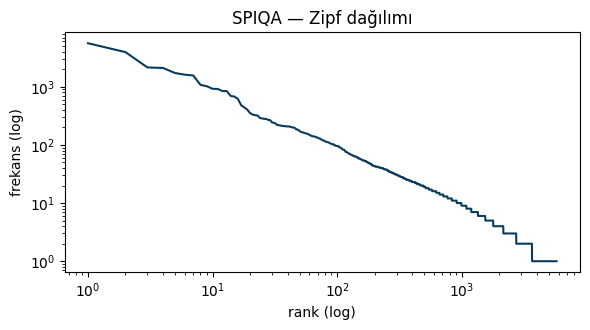

In [23]:
# Zipf yasası (log-log) — kelime tabanlı sözlüğün neden uzun kuyruklu olduğunu gösterir
freqs = sorted(vocab.values(), reverse=True)
plt.figure(figsize=(6, 3.4))
plt.loglog(range(1, len(freqs) + 1), freqs, color="#0B3C5D")
plt.xlabel("rank (log)"); plt.ylabel("frekans (log)")
plt.title("SPIQA — Zipf dağılımı"); plt.tight_layout(); plt.show()

## 6. SUBWORD TOKENIZATION — Adım 03 / bölüm 2

Alt-kelime tokenizasyonu OOV problemini **tamamen ortadan kaldırır**: bilinmeyen kelime
parçalarına ayrılır. SPIQA gibi teknik metinlerde (`hyperparameter`, `orthogonalizes`,
`WordPiece`) bu çok kritik.

Üç algoritma:
- **BPE** (GPT-2) — en sık karakter çiftlerini birleştirir
- **WordPiece** (BERT) — olabilirlik kazancına göre birleştirir, `##` ön eki kullanır
- **Unigram/SentencePiece** (T5, XLM-R) — olasılıksal budama, `▁` boşluk işareti

In [24]:
from transformers import AutoTokenizer

tok_bert = AutoTokenizer.from_pretrained("bert-base-uncased")      # WordPiece
tok_gpt2 = AutoTokenizer.from_pretrained("gpt2")                   # BPE
tok_t5   = AutoTokenizer.from_pretrained("t5-small")               # Unigram/SentencePiece

tests = [
    "The hyperparameters of the orthogonalization layer were tuned.",
    "KEHNN outperforms MV-LSTM on the Ubuntu dataset.",
    df[df.source == "question"]["clean"].iloc[1],
]
for s in tests:
    print("CÜMLE:", s[:110])
    print("  BERT  :", tok_bert.tokenize(s))
    print("  GPT-2 :", tok_gpt2.tokenize(s))
    print("  T5    :", tok_t5.tokenize(s))
    print("-" * 95)

CÜMLE: The hyperparameters of the orthogonalization layer were tuned.
  BERT  : ['the', 'hyper', '##para', '##meter', '##s', 'of', 'the', 'orthogonal', '##ization', 'layer', 'were', 'tuned', '.']
  GPT-2 : ['The', 'Ġhyper', 'param', 'eters', 'Ġof', 'Ġthe', 'Ġorth', 'og', 'onal', 'ization', 'Ġlayer', 'Ġwere', 'Ġtuned', '.']
  T5    : ['▁The', '▁hyper', 'para', 'meter', 's', '▁of', '▁the', '▁ortho', 'gon', 'al', 'ization', '▁layer', '▁were', '▁tuned', '.']
-----------------------------------------------------------------------------------------------
CÜMLE: KEHNN outperforms MV-LSTM on the Ubuntu dataset.
  BERT  : ['ke', '##hn', '##n', 'out', '##per', '##forms', 'mv', '-', 'l', '##st', '##m', 'on', 'the', 'u', '##bu', '##nt', '##u', 'data', '##set', '.']
  GPT-2 : ['KE', 'H', 'NN', 'Ġoutper', 'forms', 'ĠMV', '-', 'L', 'ST', 'M', 'Ġon', 'Ġthe', 'ĠUbuntu', 'Ġdataset', '.']
  T5    : ['▁', 'KE', 'H', 'NN', '▁out', 'per', 'form', 's', '▁', 'MV', '-', 'LS', 'TM', '▁on', '▁the', '▁Ubuntu', '▁

In [25]:
# Fertility = alt-kelime token sayısı / kelime sayısı. Düşük = korpusa daha uygun tokenizer.
sample_texts = df["clean"].sample(min(2000, len(df)), random_state=1).tolist()
n_words = sum(len(regex_tok.tokenize(t)) for t in sample_texts)

fert = []
for name, tk in [("BERT (WordPiece)", tok_bert), ("GPT-2 (BPE)", tok_gpt2), ("T5 (Unigram)", tok_t5)]:
    n_sub = sum(len(tk.tokenize(t)) for t in sample_texts)
    fert.append({"tokenizer": name, "vocab": tk.vocab_size,
                 "token": n_sub, "fertility": round(n_sub / n_words, 3)})
pd.DataFrame(fert)

,tokenizer,vocab,token,fertility
0,BERT (WordPiece),30522,71668,1.177
1,GPT-2 (BPE),50257,70630,1.160
2,T5 (Unigram),32100,77378,1.271


### 6.1 Kendi BPE tokenizer'ımızı SPIQA üzerinde eğitelim

Hazır tokenizer'lar genel web metniyle eğitildi. Alan-özel (domain-specific) bir tokenizer
daha düşük fertility verir — yani aynı metni daha az token ile ifade eder.

In [26]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers

corpus_path = "spiqa_clean_corpus.txt"
with open(corpus_path, "w", encoding="utf-8") as f:
    for t in df["clean"]:
        if t:
            f.write(t + "\n")
print("Korpus yazıldı:", corpus_path, f"{os.path.getsize(corpus_path)/1e6:.1f} MB")

bpe = Tokenizer(models.BPE(unk_token="<UNK>"))
bpe.normalizer = normalizers.Sequence([normalizers.NFKC(), normalizers.Lowercase()])
bpe.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=True)
bpe.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=8000,
    min_frequency=2,
    special_tokens=["<PAD>", "<UNK>", "<CLS>", "<SEP>", "<MASK>", "<MATH>", "<URL>", "<FIGREF>"],
)
bpe.train([corpus_path], trainer)
bpe.save("spiqa_bpe_8k.json")
print("Eğitilen sözlük boyutu:", bpe.get_vocab_size())

Korpus yazıldı: spiqa_clean_corpus.txt 0.4 MB
Eğitilen sözlük boyutu: 6511


In [27]:
for s in tests[:2]:
    print("CÜMLE:", s[:110])
    print("  SPIQA-BPE-8k :", bpe.encode(s).tokens)
    print("  GPT-2        :", tok_gpt2.tokenize(s))
    print("-" * 95)

n_sub_own = sum(len(bpe.encode(t).tokens) for t in sample_texts)
fert.append({"tokenizer": "SPIQA-BPE-8k (kendi)", "vocab": bpe.get_vocab_size(),
             "token": n_sub_own, "fertility": round(n_sub_own / n_words, 3)})

CÜMLE: The hyperparameters of the orthogonalization layer were tuned.
  SPIQA-BPE-8k : ['Ġthe', 'Ġhyperparameters', 'Ġof', 'Ġthe', 'Ġor', 'th', 'og', 'onal', 'ization', 'Ġlayer', 'Ġwere', 'Ġtuned', '.']
  GPT-2        : ['The', 'Ġhyper', 'param', 'eters', 'Ġof', 'Ġthe', 'Ġorth', 'og', 'onal', 'ization', 'Ġlayer', 'Ġwere', 'Ġtuned', '.']
-----------------------------------------------------------------------------------------------
CÜMLE: KEHNN outperforms MV-LSTM on the Ubuntu dataset.
  SPIQA-BPE-8k : ['Ġkehnn', 'Ġoutperforms', 'Ġm', 'v', '-', 'lstm', 'Ġon', 'Ġthe', 'Ġu', 'b', 'un', 'tu', 'Ġdataset', '.']
  GPT-2        : ['KE', 'H', 'NN', 'Ġoutper', 'forms', 'ĠMV', '-', 'L', 'ST', 'M', 'Ġon', 'Ġthe', 'ĠUbuntu', 'Ġdataset', '.']
-----------------------------------------------------------------------------------------------


## 7. Karşılaştırma tablosu ve grafik

,tokenizer,vocab,token,fertility
3,SPIQA-BPE-8k (kendi),6511,65796,1.080
1,GPT-2 (BPE),50257,70630,1.160
0,BERT (WordPiece),30522,71668,1.177
2,T5 (Unigram),32100,77378,1.271


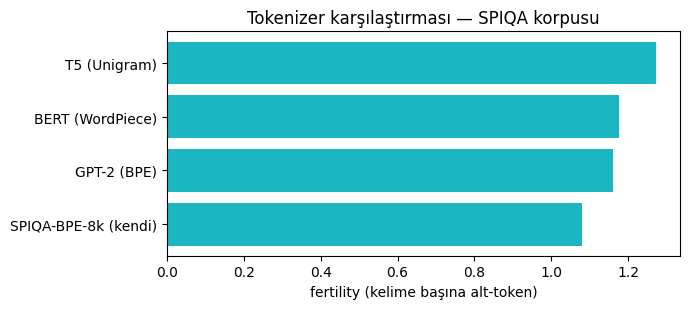

In [28]:
comp = pd.DataFrame(fert).sort_values("fertility")
display(comp)

plt.figure(figsize=(7, 3.2))
plt.barh(comp["tokenizer"], comp["fertility"], color="#1BB6C1")
plt.xlabel("fertility (kelime başına alt-token)")
plt.title("Tokenizer karşılaştırması — SPIQA korpusu")
plt.tight_layout(); plt.show()

In [29]:
# Kelime tabanlı vs alt-kelime: OOV karşılaştırması
V = 8000
kept = set(w for w, _ in vocab.most_common(V))
oov_word = 100 * sum(c for w, c in vocab.items() if w not in kept) / total
print(f"Kelime tabanlı (vocab={V:,})  OOV: {oov_word:.2f}%")
print(f"SPIQA-BPE-8k   (vocab={V:,})  OOV: 0.00%   <- alt-kelime hiç OOV üretmez")

Kelime tabanlı (vocab=8,000)  OOV: 0.00%
SPIQA-BPE-8k   (vocab=8,000)  OOV: 0.00%   <- alt-kelime hiç OOV üretmez


## 8. Çıktıları kaydet (Adım 04 — proje checkpoint'i için)

In [30]:
out_cols = ["paper_id", "source", "ref", "content_type", "figure_type", "text", "clean"]
df[out_cols].to_json("spiqa_preprocessed.jsonl", orient="records", lines=True, force_ascii=False)
sent_df[["paper_id", "source", "sents"]].rename(columns={"sents": "sentence"}) \
       .to_csv("spiqa_sentences.csv", index=False)
comp.to_csv("tokenizer_comparison.csv", index=False)

print("Kaydedilenler:")
for p in ["spiqa_preprocessed.jsonl", "spiqa_sentences.csv", "tokenizer_comparison.csv",
          "spiqa_bpe_8k.json", "spiqa_clean_corpus.txt"]:
    print(f"  {p:28s} {os.path.getsize(p)/1e6:.2f} MB")

Kaydedilenler:
  spiqa_preprocessed.jsonl     1.14 MB
  spiqa_sentences.csv          0.41 MB
  tokenizer_comparison.csv     0.00 MB
  spiqa_bpe_8k.json            0.45 MB
  spiqa_clean_corpus.txt       0.39 MB


## 9. Derste tartışılacak sorular (Adım 05)

1. `mask_math=False` yaparsanız sözlük boyutu ne kadar artıyor? LaTeX'i maskelemek bilgi kaybı mı?
2. SPIQA'da cevaplar sayısal metrik içeriyor (`0.785`, `2.1%`). `mask_num=True` yapmak QA görevi için
   neden **kötü** bir fikir olurdu?
3. Stopword listesindeki `not`, `no`, `what`, `how` kelimeleri silinirse soru anlamı ne olur?
4. Caption'lar ile rationale'lar arasında cümle uzunluğu ve fertility farkı var mı? Neden?
5. Kendi eğittiğiniz BPE, GPT-2'den düşük fertility verdi — bu her zaman daha iyi mi?
   (İpucu: önceden eğitilmiş model ağırlıkları, transfer learning)
6. `vocab_size`'ı 2000 ve 32000 yapıp fertility/sözlük dengesini çizin.

### Hızlı deney fikri
`clean_text` fonksiyonundaki bayrakları değiştirip bölüm 6'daki fertility tablosunu yeniden üretin;
hangi temizleme adımı tokenizasyonu en çok etkiliyor?